# PathSnap: model selection
Everything here is read from the logs written by `scripts/04_train_models.py`, `04b_train_fit_metrics.py`, `05_bayes_opt.py` and `06_hmm_eval.py`, with no numbers typed in by hand.
**Task framing:** binary classification of (GPS fix, candidate arc) pairs, answering "is this the fix's true road?". Probabilities are normalised per fix.
**Protocol:** 5-fold GroupKFold on 78 TRAIN trips (grouped by trip, so there is no leakage), then refit on all TRAIN, then one evaluation on 10 STUDENT_TEST trips.
**Primary metric:** observation-level Top-1 accuracy. Log loss also matters because the HMM uses the probabilities.

In [1]:
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
R = '../results'
info = pd.read_csv(f'{R}/models/student_test_results.csv').set_index('model')[['family','config']]
info

,family,config
model,,
GaussNB,Linear / probabilistic,"GaussianNB on signed-log1p + scaled features, ..."
LogReg,Linear / probabilistic,StandardScaler(signed log1p) + L2 LogisticRegr...
LightGBM,Boosting,"GBDT 400 rounds, lr=0.05, num_leaves=63, subsa..."
XGBoost,Boosting,"hist, 400 rounds, eta=0.05, max_depth=7, subsa..."
MLP,Neural network,"MLP (64,32) ReLU, adam lr=1e-3, batch 1024, ea..."
KNN,Instance-based,"distance-weighted KNN k=25, scaled; fitted on ..."
RandomForest,Ensemble (bagging),"150 trees, min_samples_leaf=10, max_samples=0...."


## 1. Cross-validation (TRAIN, 5-fold GroupKFold)

In [2]:
cv = pd.read_csv(f'{R}/models/cv_folds.csv')
cvs = cv.groupby('model').agg(macro_f1=('macro_f1','mean'), macro_f1_sd=('macro_f1','std'), top1=('top1_acc','mean'),
                              log_loss=('log_loss','mean'), train_s_per_fold=('train_s','mean')).sort_values('macro_f1', ascending=False)
cvs.round(4)

,macro_f1,macro_f1_sd,top1,log_loss,train_s_per_fold
model,,,,,
XGBoost,0.9396,0.0104,0.8925,0.0925,19.3453
LightGBM,0.9392,0.0103,0.8924,0.0935,16.7309
RandomForest,0.9385,0.0107,0.8903,0.0944,69.2291
MLP,0.9344,0.0112,0.8887,0.1023,22.6638
KNN,0.9210,0.0125,0.8746,0.1515,0.0561
LogReg,0.9161,0.0114,0.8799,0.1320,1.8058
GaussNB,0.7881,0.0152,0.8012,1.1369,0.5489


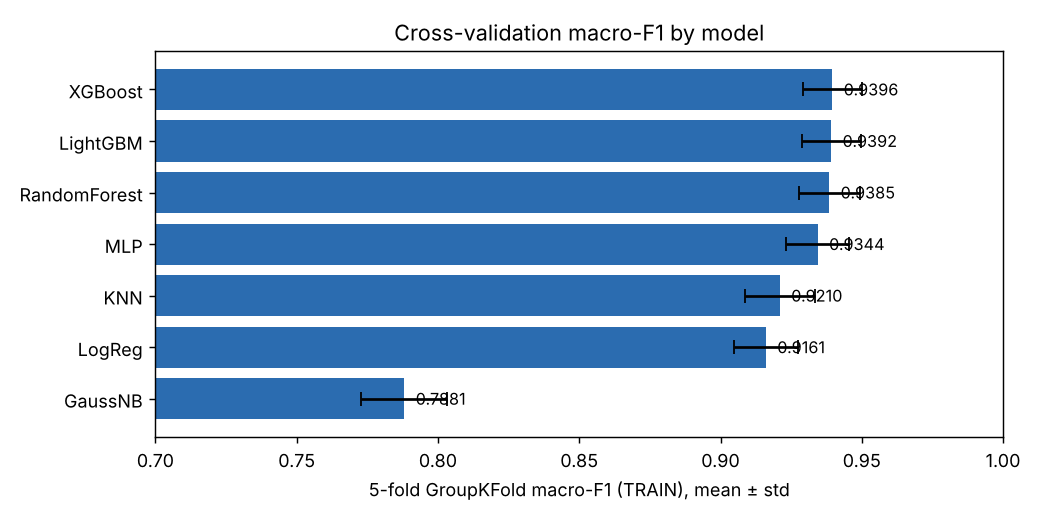

In [3]:
display(Image(f'{R}/figures/cv_macro_f1.png', width=700))

The top three (XGBoost, LightGBM, Random Forest) differ by about 0.001 in macro-F1, while the fold-to-fold std is about 0.010. **They are statistically tied on CV.**

## 2. Student-test comparison (classifier only)

In [4]:
te = pd.read_csv(f'{R}/models/student_test_results.csv').set_index('model')
te[['top1_acc','macro_f1','precision_pos','recall_pos','log_loss','route_continuity','candidate_miss_rate','train_s','infer_s']].sort_values('top1_acc', ascending=False).round(4)

,top1_acc,macro_f1,precision_pos,recall_pos,log_loss,route_continuity,candidate_miss_rate,train_s,infer_s
model,,,,,,,,,
LightGBM,0.9005,0.9365,0.9042,0.8841,0.0894,0.9423,0.0042,20.3453,1.1855
XGBoost,0.8983,0.9354,0.9032,0.8814,0.0894,0.9431,0.0042,20.9776,0.3591
MLP,0.8941,0.9317,0.8971,0.8753,0.0977,0.9422,0.0042,25.1512,0.0369
RandomForest,0.8906,0.9328,0.9052,0.8708,0.0921,0.9368,0.0042,92.9884,0.6972
LogReg,0.8807,0.9149,0.8730,0.8434,0.1269,0.9302,0.0042,2.1881,0.0195
KNN,0.8751,0.9158,0.9076,0.8144,0.1464,0.9287,0.0042,0.0433,8.0758
GaussNB,0.8019,0.7854,0.5276,0.9147,1.0975,0.9018,0.0042,0.4662,0.0205


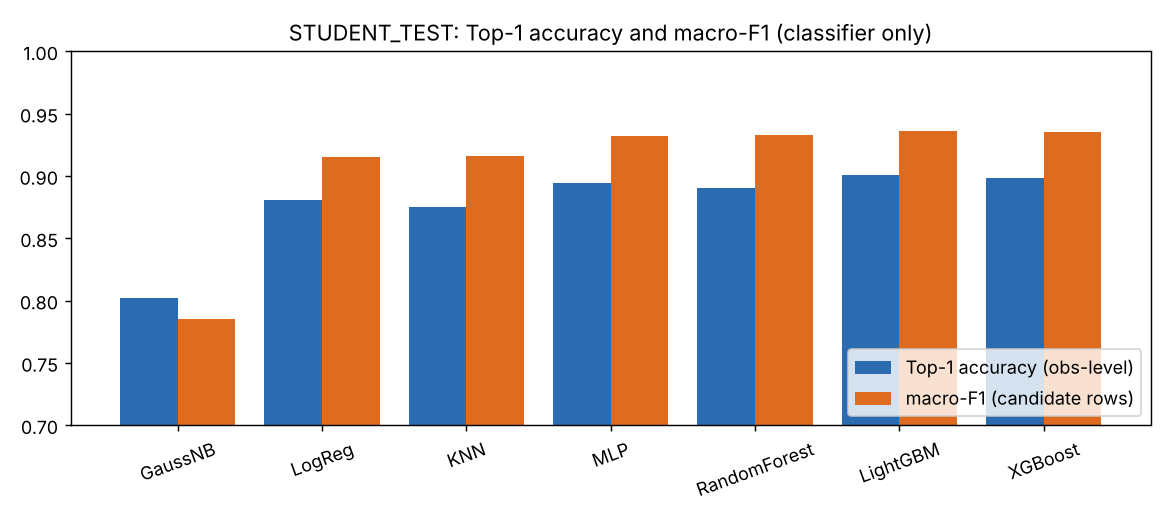

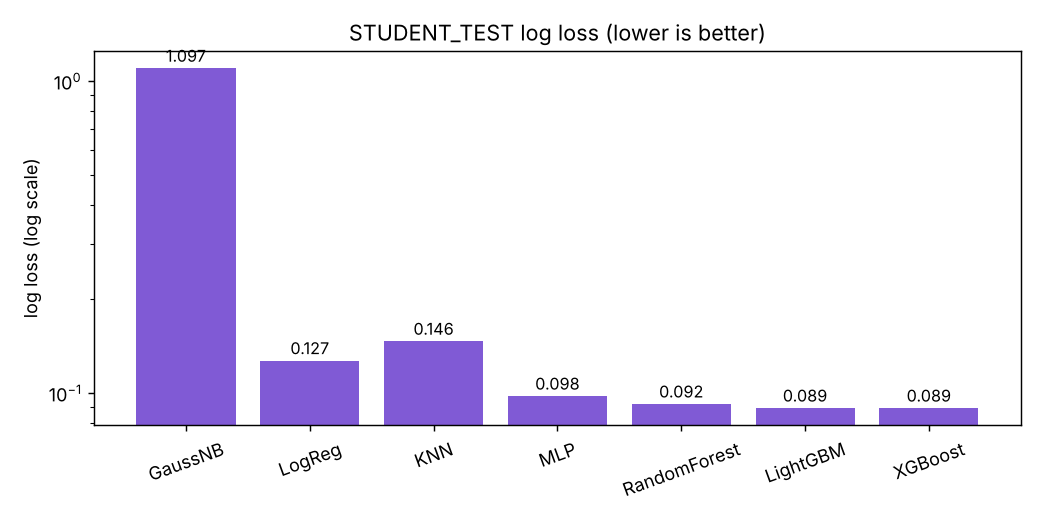

In [5]:
display(Image(f'{R}/figures/student_test_top1_f1.png', width=750)); display(Image(f'{R}/figures/student_test_logloss.png', width=650))

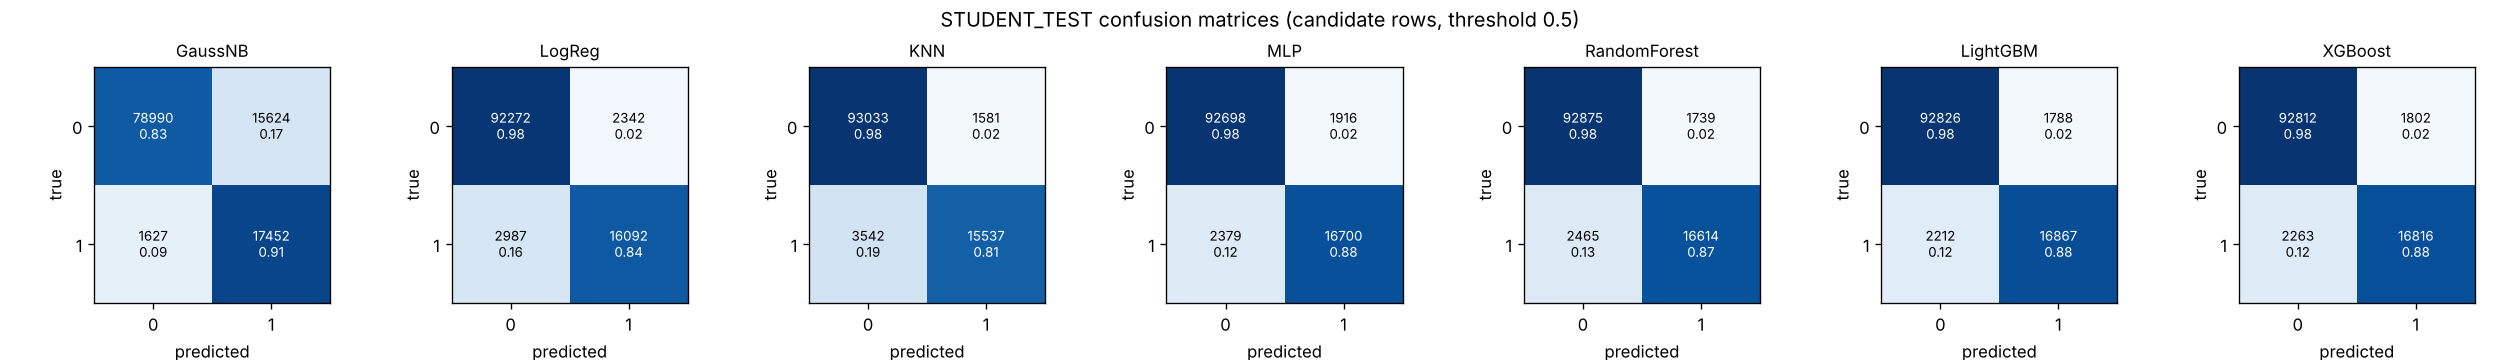

In [6]:
display(Image(f'{R}/figures/confusion_matrices.png'))

## 3. Over/under-fitting check

In [7]:
tf = pd.read_csv(f'{R}/models/train_fit_metrics.csv').set_index('model')
o = pd.DataFrame({'train_top1': tf.train_top1, 'cv_top1': cvs.top1, 'test_top1': te.top1_acc})
o['train_minus_cv'] = o.train_top1 - o.cv_top1
o.sort_values('test_top1', ascending=False).round(4)

,train_top1,cv_top1,test_top1,train_minus_cv
model,,,,
LightGBM,0.9306,0.8924,0.9005,0.0382
XGBoost,0.9271,0.8925,0.8983,0.0346
MLP,0.9064,0.8887,0.8941,0.0177
RandomForest,0.9067,0.8903,0.8906,0.0164
LogReg,0.8804,0.8799,0.8807,0.0006
KNN,0.8888,0.8746,0.8751,0.0142
GaussNB,0.8019,0.8012,0.8019,0.0008


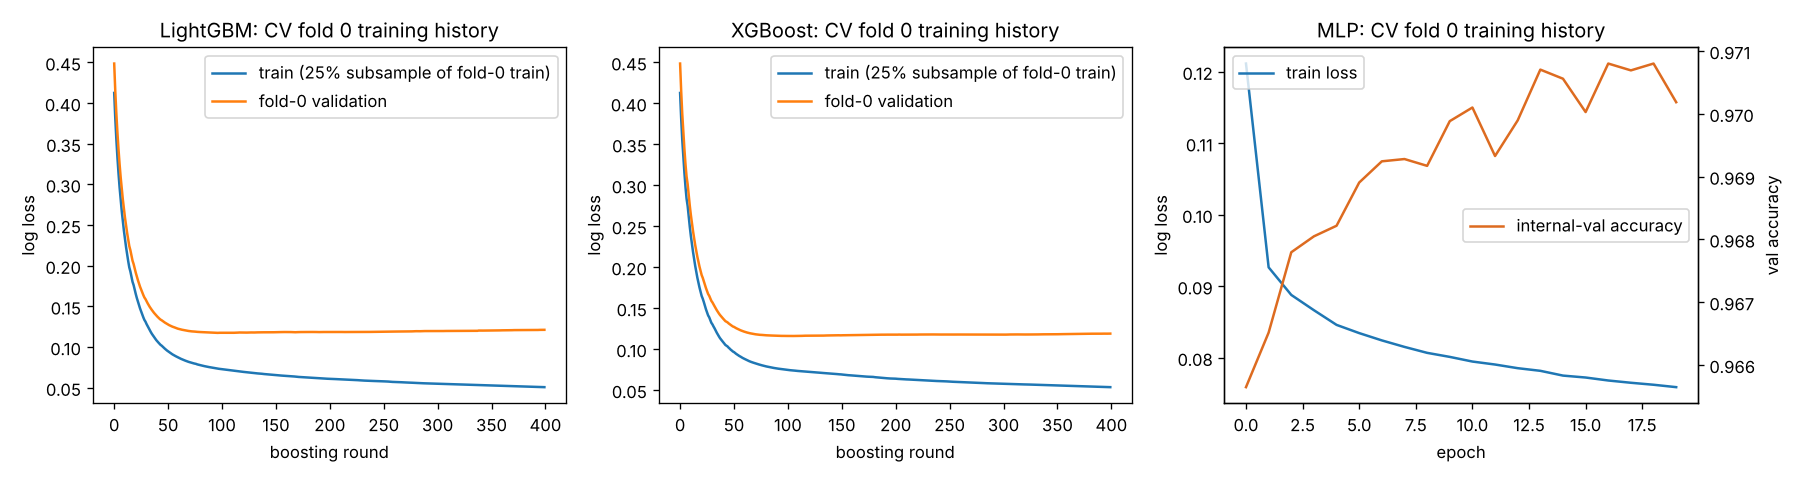

In [8]:
display(Image(f'{R}/figures/training_histories.png'))

LightGBM and XGBoost overfit mildly (train is about 3.5–3.8 points above CV), but CV and test agree, so they generalise. GaussNB and LogReg have no train–CV gap and low scores, which is **underfitting**: the models are too simple, or (for NB) their independence assumption is wrong.

## 4. Error analysis: why ~10 % of fixes are still wrong

In [9]:
ea = json.load(open(f'{R}/models/error_analysis_lightgbm_test.json')); ea

{'n_errors': 1907,
 'reverse_twin_of_truth': 0.42003146303093863,
 'shares_node_with_truth': 0.7871001573151547,
 'truth_not_in_candidates': 0.042475091767173574}

Most errors pick the **reverse twin** of the correct arc, or an arc that shares a node with it (an intersection). Those are sequential, local confusions, so we add the HMM rather than more tuning.

## 5. Bayesian hyperparameter optimisation (Optuna TPE) on LightGBM

In [10]:
bp = json.load(open(f'{R}/bayes/best_params.json')); print(json.dumps(bp['best_params'], indent=1)); print('trials:', bp['n_trials'])
pd.read_csv(f'{R}/bayes/tuned_vs_untuned.csv', index_col=0)[['cv5_macro_f1','cv5_top1','cv5_log_loss','test_top1','test_macro_f1','test_log_loss','train_s','infer_s']].round(4)

{
 "num_leaves": 102,
 "learning_rate": 0.09477972652122088,
 "n_estimators": 500,
 "min_child_samples": 77,
 "subsample": 0.9447648932021865,
 "colsample_bytree": 0.7515881340861911,
 "reg_lambda": 1.296627033382355
}
trials: 20


,cv5_macro_f1,cv5_top1,cv5_log_loss,test_top1,test_macro_f1,test_log_loss,train_s,infer_s
untuned,0.9392,0.8924,0.0935,0.9005,0.9365,0.0894,18.4634,1.1076
tuned,0.9392,0.8939,0.0979,0.9004,0.9361,0.0920,29.9438,1.5999


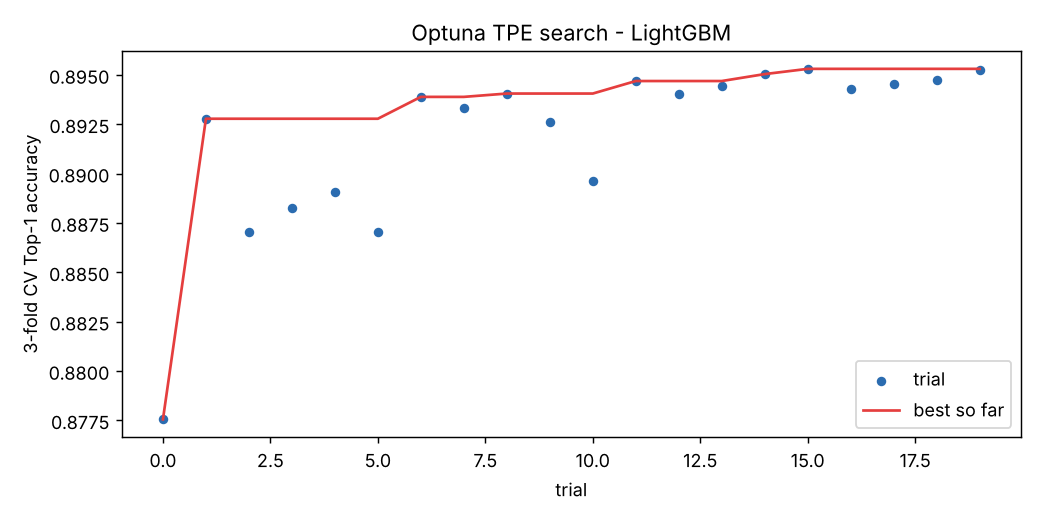

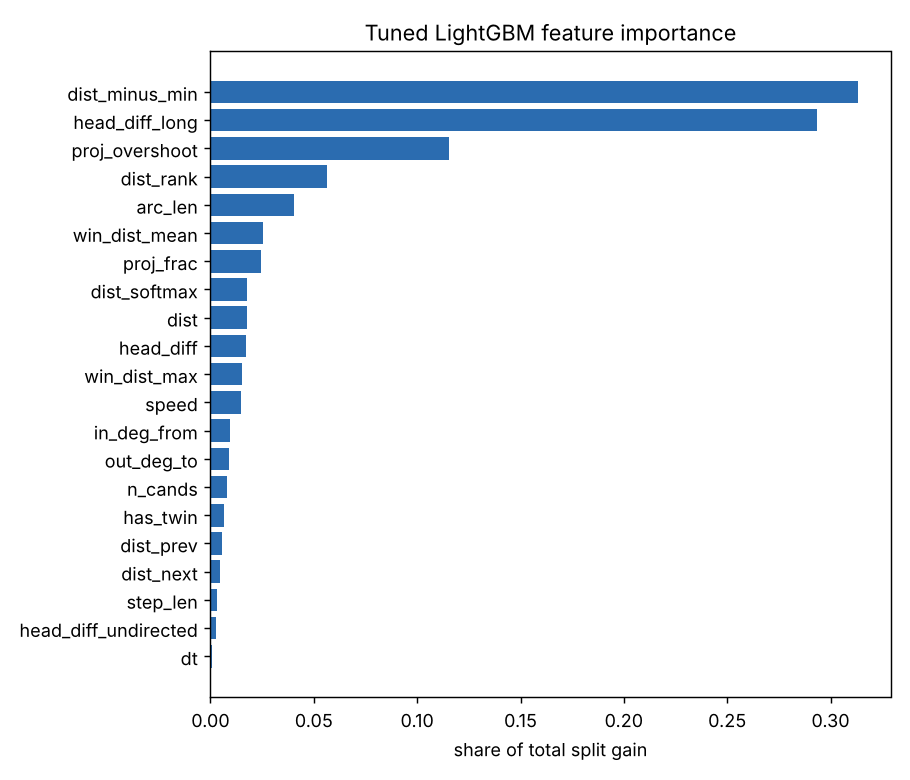

In [11]:
display(Image(f'{R}/figures/bayes_history.png', width=650)); display(Image(f'{R}/figures/feature_importance.png', width=550))

## 6. HMM/Viterbi decoding on top of every classifier (STUDENT_TEST)

In [12]:
h = pd.read_csv(f'{R}/hmm/student_test_summary.csv', index_col=0)
h['gain_pts'] = 100 * (h.hmm_top1 - h.clf_top1)
h[['clf_top1','hmm_top1','gain_pts','clf_continuity','hmm_continuity']].sort_values('hmm_top1', ascending=False).round(4)

,clf_top1,hmm_top1,gain_pts,clf_continuity,hmm_continuity
tuned_LightGBM,0.9004,0.9251,2.4687,0.9449,0.9816
LightGBM,0.9005,0.9241,2.3591,0.9419,0.9818
XGBoost,0.8983,0.9219,2.3643,0.9434,0.9813
RandomForest,0.8906,0.9200,2.9489,0.9359,0.9816
MLP,0.8941,0.9191,2.5000,0.9420,0.9813
LogReg,0.8807,0.9121,3.1367,0.9308,0.9807
KNN,0.8751,0.9088,3.3768,0.9298,0.9801
GaussNB,0.8019,0.8904,8.8518,0.9110,0.9727
Gaussian_HMM_no_classifier,0.9004,0.8867,-1.3727,0.9449,0.9796


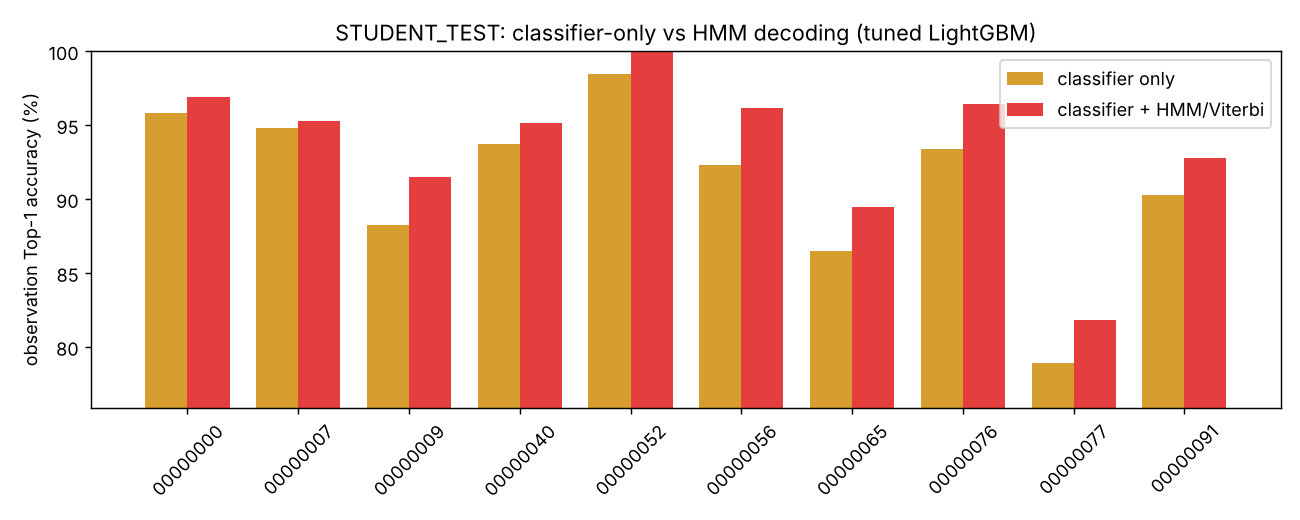

In [13]:
display(Image(f'{R}/figures/hmm_vs_clf_per_trip.png'))

## 7. Decision
- **Selected: LightGBM.** It is tied with XGBoost and RF on CV, and wins on student-test Top-1 (90.05 %), joint-best log loss (0.089, which matters for HMM emissions), and training time (4× faster than RF).
- **Rejected: GaussNB.** Its features are strongly correlated (several distances to the same arc), so it double-counts evidence and is overconfident (log loss 1.10).
- **Tuning** gave no meaningful gain, because the remaining errors are twin/intersection ambiguity, not hyperparameters.
- **The HMM is the biggest lever:** tuned LightGBM goes from 90.04 % to **92.51 %** Top-1 and from 94.5 % to 98.2 % continuity, and improves all 10 test trips.